In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, 
                             classification_report, precision_score, 
                             recall_score, f1_score, roc_auc_score, 
                             roc_curve)

In [5]:
data = pd.read_csv('diabetes.csv')

print("Dataset Shape:", data.shape)
print("\nFirst 5 rows:\n", data.head())
print("\nDataset Info:\n")
data.info()

Dataset Shape: (768, 9)

First 5 rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Info:

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null 

In [6]:
print("\nStatistical Summary:\n", data.describe())


Statistical Summary:
        Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.0

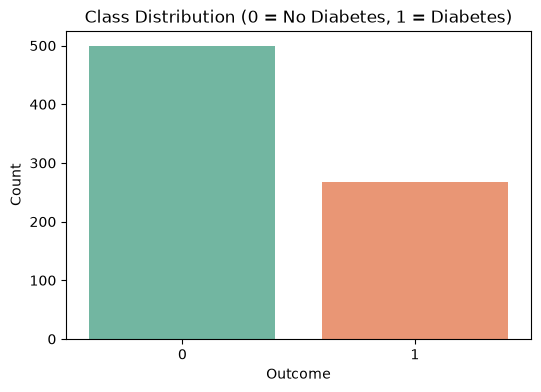

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='Outcome', hue='Outcome', palette='Set2', legend=False)
plt.title('Class Distribution (0 = No Diabetes, 1 = Diabetes)')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

In [10]:
print("\nMissing Values:\n", data.isnull().sum())


Missing Values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [11]:
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Count zeros before replacement
print("Zeros before replacement:\n")
for col in cols_with_zeros:
    print(f"{col}: {(data[col] == 0).sum()}")

# Replace zeros with NaN
for col in cols_with_zeros:
    data[col] = data[col].replace(0, np.nan)

# Impute with median
for col in cols_with_zeros:
    data[col] = data[col].fillna(data[col].median())

print("\nMissing values after imputation:\n", data.isnull().sum())

Zeros before replacement:

Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11

Missing values after imputation:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


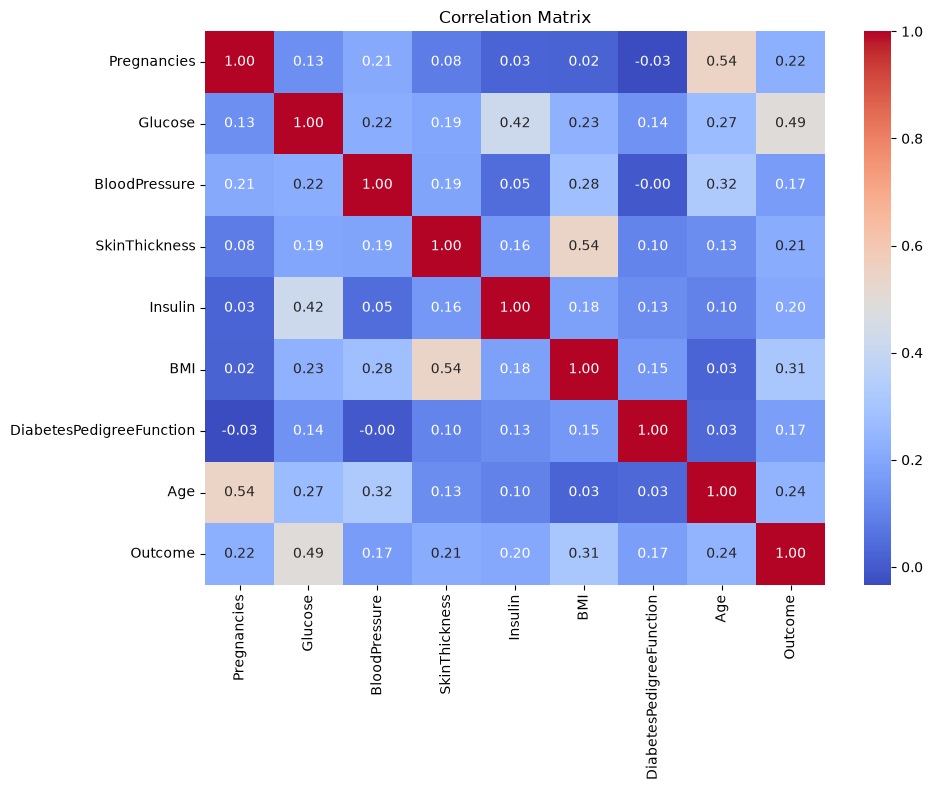

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [13]:
X = data.drop('Outcome', axis=1)
y = data['Outcome']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (614, 8)
Testing set: (154, 8)


In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

print("Model trained successfully!")
print("Intercept:", log_model.intercept_)
print("Coefficients:\n", dict(zip(X.columns, log_model.coef_[0])))

Model trained successfully!
Intercept: [-0.87215537]
Coefficients:
 {'Pregnancies': np.float64(0.3775023452572799), 'Glucose': np.float64(1.182511437316831), 'BloodPressure': np.float64(-0.044065796014798174), 'SkinThickness': np.float64(0.028225186008252467), 'Insulin': np.float64(-0.06615746318853263), 'BMI': np.float64(0.6887347098715281), 'DiabetesPedigreeFunction': np.float64(0.23338637833551307), 'Age': np.float64(0.1477984842811931)}


In [17]:
# Class predictions (0 or 1)
y_pred = log_model.predict(X_test_scaled)

# Probability predictions (for ROC-AUC)
y_pred_proba = log_model.predict_proba(X_test_scaled)[:, 1]

In [18]:
print("\n========== MODEL EVALUATION ==========")
print(f"Accuracy : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred) * 100:.2f}%")
print(f"Recall   : {recall_score(y_test, y_pred) * 100:.2f}%")
print(f"F1-Score : {f1_score(y_test, y_pred) * 100:.2f}%")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_proba):.4f}")

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))


========== MODEL EVALUATION ==========
Accuracy : 70.78%
Precision: 60.00%
Recall   : 50.00%
F1-Score : 54.55%
ROC-AUC  : 0.8130

Confusion Matrix:
 [[82 18]
 [27 27]]

Classification Report:
               precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



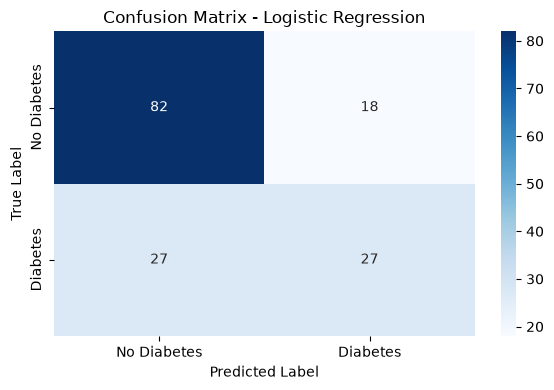

In [19]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

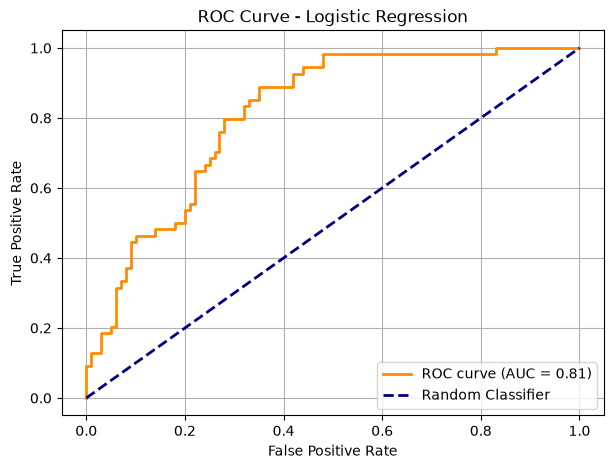

In [20]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [23]:
# Convert to numpy arrays first
X_train_np = X_train.values
X_test_np = X_test.values

# Fit scaler on numpy array (no feature names)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_np)
X_test_scaled = scaler.transform(X_test_np)

# Now the new sample (numpy array) won't trigger a warning
sample = np.array([[6, 148, 72, 35, 0, 33.6, 0.627, 50]])
sample_scaled = scaler.transform(sample)   # No warning

In [24]:
# Example: a new patient's data
sample = np.array([[6, 148, 72, 35, 0, 33.6, 0.627, 50]])

# Scale the sample
sample_scaled = scaler.transform(sample)

# Predict
prediction = log_model.predict(sample_scaled)
probability = log_model.predict_proba(sample_scaled)[0][1]

print(f"\nPrediction: {'Diabetes' if prediction[0] == 1 else 'No Diabetes'}")
print(f"Probability of Diabetes: {probability * 100:.2f}%")


Prediction: Diabetes
Probability of Diabetes: 72.72%


In [25]:
log_model_balanced = LogisticRegression(
    max_iter=1000, random_state=42, class_weight='balanced'
)
log_model_balanced.fit(X_train_scaled, y_train)
y_pred_bal = log_model_balanced.predict(X_test_scaled)

print("\n===== Balanced Logistic Regression =====")
print(f"Accuracy : {accuracy_score(y_test, y_pred_bal) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred_bal) * 100:.2f}%")
print(f"Recall   : {recall_score(y_test, y_pred_bal) * 100:.2f}%")
print(f"F1-Score : {f1_score(y_test, y_pred_bal) * 100:.2f}%")


===== Balanced Logistic Regression =====
Accuracy : 73.38%
Precision: 60.32%
Recall   : 70.37%
F1-Score : 64.96%


In [27]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'saga']       # no penalty parameter at all
}

grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", round(grid.best_score_ * 100, 2), "%")

Best Parameters: {'C': 1, 'solver': 'lbfgs'}
Best CV Score: 78.18 %
